# Pairwise amino-acid identity of the tree datasets

How divergent the sequences behind the *Flaviviridae* (Fig. 2b, Supplementary Fig. 5) and *Filoviridae*
(Fig. 2a) trees are, as ordinary pairwise amino-acid identity. This is the evidence for the claim that
these trees are built in the twilight zone, where sequence-based inference becomes unreliable.

Identities are read off a MAFFT alignment of each dataset: for a pair, the fraction of alignment columns
where both sequences have a residue and the residues are identical. The *Filoviridae* numbers are for the
14 species representatives of Fig. 2a, taken out of the alignment of all 550 unique sequences, so every
pair is aligned with the full set of homologues to guide it.

The 550 sequences themselves are **not** summarised as one distribution: the genera are sampled very
unevenly in GenBank (472 *Orthoebolavirus* against 1-3 sequences for each of four genera), so 90% of
between-genus pairs are the single *Orthoebolavirus*-*Orthomarburgvirus* comparison and the pooled
distribution would describe sequencing effort rather than filovirus diversity. The species
representatives weight each species once, as the Fig. 2a species tree does.

Inputs: `../flaviviridae/inputs/refolded_fullglyco_{E,E1,E2}_aa.fas` (as in `flaviviridae_trees.ipynb`,
without the sequences that have no viral group), the deduplicated GP FASTA and
`../filoviridae/results/filoviridae_gp_accessions.csv` (as in `filoviridae_trees.ipynb`).
Outputs: `results/pairwise_identity.csv`, `figures/pairwise_identity.{pdf,png}`.

In [1]:
# Re-import the shared style when it changes, without restarting the kernel
%load_ext autoreload
%autoreload 2

import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

sys.path.insert(0, "../../../../benchmarks")  # the shared figure style, and the KDE of Supplementary Fig. 2b
from fig_panels import kde_reflected
from pub_style import MM, MUTED_TEXT, REFERENCE_LINEWIDTH, WIDTH_SINGLE, save_pub, use_pub_style

use_pub_style()

FLAVI_DIR = Path("../flaviviridae/inputs")
FILO_FASTA = Path("/scratch/fweikert/phylogeny/filoviridae_deduplicated/inputs/gp_dedup.fasta")
WORK = Path("/scratch/fweikert/phylogeny/pairwise_identity")   # MAFFT alignments (not tracked)
RESULT_DIR = Path("results")
FIGURE_DIR = Path("figures")
MAFFT = "module load gcc/11.5.0 mafft/7.525"                   # cluster module, as in filoviridae_trees.ipynb
WORK.mkdir(parents=True, exist_ok=True)

FLAVI = {"E": "refolded_fullglyco_E_aa.fas", "E1": "refolded_fullglyco_E1_aa.fas",
         "E2": "refolded_fullglyco_E2_aa.fas"}
TWILIGHT = (20, 35)   # the conventional twilight zone of pairwise amino-acid identity

In [2]:
def read_fasta(path):
    """[(name, sequence)] with the name cut at the first space, sequences upper case."""
    records, name, parts = [], None, []
    for line in Path(path).read_text().splitlines():
        if line.startswith(">"):
            if name is not None:
                records.append((name, "".join(parts)))
            name, parts = line[1:].split()[0], []
        elif line.strip():
            parts.append(line.strip().upper())
    return records + ([(name, "".join(parts))] if name is not None else [])


def write_fasta(records, path):
    """Write `records`, leaving the file untouched if it already has exactly this content, so that
    its modification time (and with it the cached alignment) stays valid."""
    text = "".join(f">{name}\n{sequence}\n" for name, sequence in records)
    path = Path(path)
    if not path.exists() or path.read_text() != text:
        path.write_text(text)
    return path


def align(fasta, name):
    """MAFFT --auto alignment of `fasta`, cached in WORK under `name`.

    Single-threaded: with several threads MAFFT returns a different alignment from run to run,
    which moves the identities in the second decimal place."""
    output = WORK / f"{name}.msa"
    if not output.exists() or output.stat().st_mtime < Path(fasta).stat().st_mtime:
        subprocess.run(["bash", "-lc", f"{MAFFT} && mafft --auto --quiet --thread 1 {fasta} > {output}"],
                       check=True)
    return output


# Flaviviridae: the sequences that go into the trees, i.e. without those whose group code ends in UN
alignments = {}
for dataset, fasta in FLAVI.items():
    records = read_fasta(FLAVI_DIR / fasta)
    classified = [(name, sequence) for name, sequence in records if not name.split("_")[0].endswith("UN")]
    print(f"{dataset}: {len(records)} sequences, {len(classified)} with a group")
    alignments[dataset] = align(write_fasta(classified, WORK / f"{dataset}.fasta"), dataset)

# Filoviridae: all 550 unique GP sequences, so the 14 representatives are aligned among their homologues
alignments["GP"] = align(FILO_FASTA, "GP")
print("GP:", len(read_fasta(FILO_FASTA)), "unique sequences")

E: 247 sequences, 236 with a group
E1: 190 sequences, 189 with a group
E2: 189 sequences, 188 with a group
GP: 550 unique sequences


In [3]:
def pairwise_identity(alignment, keep=None):
    """(names, matrix) of pairwise identity over the columns where both sequences have a residue.

    `keep`: names to restrict to, as a set; the alignment itself is always the full one."""
    records = [(name, sequence) for name, sequence in read_fasta(alignment)
               if keep is None or name in keep]
    names = [name for name, _ in records]
    columns = np.array([list(sequence) for _, sequence in records], dtype="S1")
    residue = ~np.isin(columns, [b"-", b"."])
    identity = np.full((len(names), len(names)), np.nan)
    for i in range(len(names)):
        both = residue[i + 1:] & residue[i]
        identity[i, i + 1:] = ((columns[i + 1:] == columns[i]) & both).sum(1) / both.sum(1)
    return names, 100 * identity


def upper(matrix, mask=None):
    """The upper triangle of `matrix` as a flat array, optionally only where `mask` is true."""
    triangle = ~np.isnan(matrix)
    return matrix[triangle & mask] if mask is not None else matrix[triangle]


# Flaviviridae: every pair within a glycoprotein dataset
identities, sequences = {}, {}
for dataset, alignment in alignments.items():
    if dataset != "GP":
        names, matrix = pairwise_identity(alignment)
        identities[dataset], sequences[dataset] = upper(matrix), len(names)

# Filoviridae: the 14 species representatives, split by whether the pair crosses a genus
accessions = pd.read_csv(Path("../filoviridae/results/filoviridae_gp_accessions.csv"))
species = dict(zip(accessions["accession"], accessions["species"]))
representatives = set(accessions.loc[accessions["species_representative"], "accession"])
names, matrix = pairwise_identity(alignments["GP"], keep=representatives)
genus = np.array([species[name].split()[0] for name in names])
same_genus = genus[:, None] == genus[None, :]
for label, mask in [("Between genera", ~same_genus), ("Within genus", same_genus)]:
    identities[label], sequences[label] = upper(matrix, mask), len(names)
print(f"{len(names)} species representatives, {len(set(genus))} genera")

# All 550 unique sequences, by taxonomic level: reported in the table for completeness but not
# drawn, because the genera are sampled very unevenly and the shape would follow that sampling
names, matrix = pairwise_identity(alignments["GP"])
species_of = np.array([species[name] for name in names])
genus_of = np.array([name.split()[0] for name in species_of])
same_species = species_of[:, None] == species_of[None, :]
same_genus = genus_of[:, None] == genus_of[None, :]
complete = {"All 550, within species": same_species,
            "All 550, within genus": same_genus & ~same_species,
            "All 550, between genera": ~same_genus}
complete = {label: upper(matrix, mask) for label, mask in complete.items()}
sequences.update({label: len(names) for label in complete})

summary = pd.DataFrame([
    dict(dataset=dataset, sequences=sequences[dataset], pairs=len(values),
         median=np.median(values), mean=values.mean(), minimum=values.min(), maximum=values.max(),
         percent_below_20=100 * (values < 20).mean(), percent_below_35=100 * (values < 35).mean())
    for dataset, values in {**identities, **complete}.items()]).round(1)
RESULT_DIR.mkdir(exist_ok=True)
summary.to_csv(RESULT_DIR / "pairwise_identity.csv", index=False)
summary

14 species representatives, 6 genera


,dataset,sequences,pairs,median,mean,minimum,maximum,percent_below_20,percent_below_35
0,E,236,27730,15.6,22.1,4.1,100.0,72.0,82.7
1,E1,189,17766,20.5,23.1,5.5,100.0,46.3,88.9
2,E2,188,17578,18.4,21.5,6.5,100.0,65.0,90.5
3,Between genera,14,72,16.7,21.9,9.8,58.3,62.5,94.4
4,Within genus,14,19,60.2,60.6,45.8,76.2,0.0,0.0
5,"All 550, within species",550,89751,93.3,89.4,23.5,100.0,0.0,0.4
6,"All 550, within genus",550,23894,59.3,58.7,12.7,76.7,0.2,1.6
7,"All 550, between genera",550,37330,31.1,29.1,3.9,59.6,8.8,99.3


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


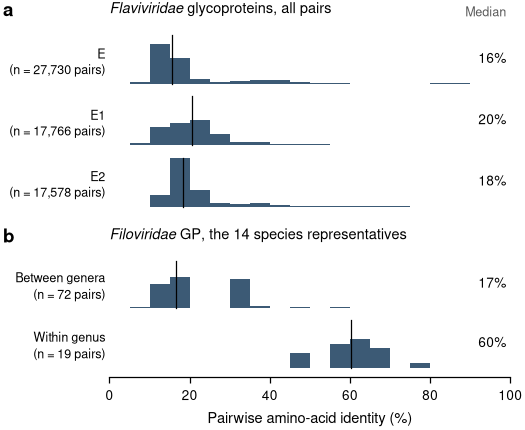

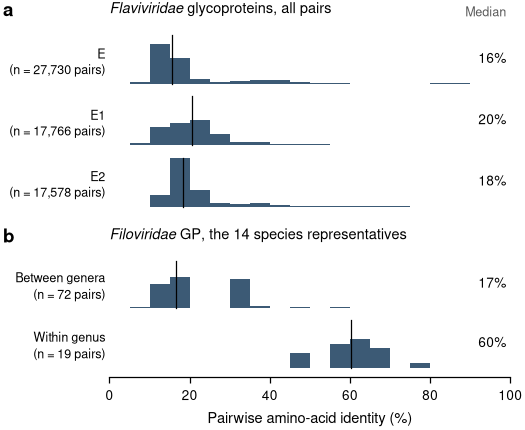

In [4]:
# Figure (not in the paper): a, the Flaviviridae datasets; b, the Filoviridae species representatives.
# One row per comparison, one colour and one bar scale throughout, so only position and shape carry
# information; the two panels share the identity axis.
BIN = 5                     # width of a histogram bin, in identity per cent
ROW_HEIGHT = 0.8            # of the row spacing, for the tallest bar in the figure
BAR_COLOUR = "#3C5A75"
PANELS = [(r"$\it{Flaviviridae}$ glycoproteins, all pairs", ["E", "E1", "E2"]),
          (r"$\it{Filoviridae}$ GP, the 14 species representatives",
           ["Between genera", "Within genus"])]

edges = np.arange(0, 100 + BIN, BIN)
fractions = {dataset: 100 * np.histogram(identities[dataset], bins=edges)[0] / len(identities[dataset])
             for _, group in PANELS for dataset in group}
scale = ROW_HEIGHT / max(fraction.max() for fraction in fractions.values())

fig = plt.figure(figsize=(WIDTH_SINGLE, 74 * MM), layout="constrained")
axes = fig.subplots(len(PANELS), 1, sharex=True,
                    height_ratios=[len(group) for _, group in PANELS])

for ax, (title, group) in zip(axes, PANELS):
    for row, dataset in enumerate(group):
        ax.stairs(row - scale * fractions[dataset], edges, baseline=row, fill=True, color=BAR_COLOUR,
                  lw=0, zorder=3)
        median = np.median(identities[dataset])
        ax.plot([median, median], [row, row - ROW_HEIGHT], color="black", lw=0.6, zorder=4)
        ax.text(99, row - ROW_HEIGHT / 2, f"{median:.0f}%", ha="right", va="center", fontsize=6.5)
    ax.set_xlim(0, 100)
    ax.set_ylim(len(group) - 1 + 0.15, -ROW_HEIGHT - 0.25)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(20))
    ax.set_yticks([row - ROW_HEIGHT / 2 for row in range(len(group))],
                  [f"{dataset}\n(n = {len(identities[dataset]):,} pairs)" for dataset in group],
                  fontsize=6, linespacing=1.35)
    ax.tick_params(axis="y", length=0, pad=2)
    ax.spines["left"].set_visible(False)
    ax.set_title(title, loc="left", pad=3)

# One identity axis for both panels, at the foot of the figure
for ax in axes[:-1]:
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(axis="x", length=0)
axes[0].text(99, 1.0, "Median", color=MUTED_TEXT, transform=axes[0].get_xaxis_transform(),
             ha="right", va="bottom", fontsize=6)
axes[-1].set_xlabel("Pairwise amino-acid identity (%)")

fig.canvas.draw()
fig.set_layout_engine("none")
for ax, letter in zip(axes, "ab"):
    box = ax.get_tightbbox().transformed(fig.transFigure.inverted())
    fig.text(0, box.y1, letter, fontsize=9, fontweight="bold", ha="left", va="top")

save_pub(fig, "pairwise_identity", FIGURE_DIR)
fig